# Final Model: Downscaling SME2 to 100 m and 50 m

Machine learning learns one number, **β**: the change in soil moisture per 1 dB of HH brightness. NASA's downscaling
equation then uses β to split each 200 m SME2 value into 100 m and 50 m pieces.

1. Two ways to learn β: **Absolute** (predict SME2) and **Anomaly** (predict block minus field on the same day).
2. Two models, Ridge and Random Forest, on two data sets: Clean fallow, and Clean + Mixed + Edge.
3. Testing is nested leave-one-date-out cross-validation: 6 folds grouped by date, settings tuned inside each fold, all
   scored on the soil moisture pattern inside the field.
4. The best β is applied at 100 m and 50 m.

## 1. Data

| Data set | Blocks | Records | Role |
|---|---|---|---|
| **Clean fallow** | B0_0 to B0_3 | 4 × 6 dates = 24 | Learns and tests β; the only blocks mapped at 100 m and 50 m |
| **Clean + Mixed + Edge** | all fallow blocks, rows 0 and 1 | 10 × 6 dates = 60 | Stress test: the same steps with almond and partial-cover blocks added |

The data preparation notebook counts 48 Clean records: 24 fallow and 24 almond. Almond blocks are not used here, so Clean
fallow (24) is the training set and the 60 records are a test of what happens without the block filter.

In [48]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score

PROCESSED_FOLDER = "../Processed Data"     # run from the Code folder
INPUT_FILE = os.path.join(PROCESSED_FOLDER, "Downscaling_Dataset.xlsx")
OUTPUT_FILE = os.path.join(PROCESSED_FOLDER, "Final_Soil_Moisture_Results.xlsx")
MAP_BLOCKS = ["B0_0", "B0_1", "B0_2", "B0_3"]   # the Clean fallow blocks

blocks = pd.read_excel(INPUT_FILE, sheet_name="Blocks 200m")
pieces = {"100m": pd.read_excel(INPUT_FILE, sheet_name="Pieces 100m"),
          "50m": pd.read_excel(INPUT_FILE, sheet_name="Pieces 50m")}
for table in [blocks, pieces["100m"], pieces["50m"]]:
    table["Date"] = pd.to_datetime(table["Date"]).dt.strftime("%Y-%m-%d")

fallow = blocks[blocks["Crop"] == "Fallow"]
data_sets = {"Clean fallow": fallow[fallow["Block_Type"] == "Clean"],
             "Clean + Mixed + Edge": fallow}

for name, table in data_sets.items():
    print(f"{name}: {table['Block_ID'].nunique()} blocks x {table['Date'].nunique()} dates = {len(table)} records")

Clean fallow: 4 blocks x 6 dates = 24 records
Clean + Mixed + Edge: 10 blocks x 6 dates = 60 records


## 2. Features

**HH_dB** is the moisture signal, **HV_dB** the vegetation signal and **HV_HH_Ratio** separates canopy from bare soil.
**Anomalies** (block minus field on the same date) remove weather and pass effects shared by the whole field.

- The ratio stays in linear units: in dB it would equal HV_dB − HH_dB and add nothing new.
- Field radar is pixel-weighted (more pixels, more ground seen). Field SME2 is a plain block average, because each SME2
  value covers its whole 200 m cell.

In [49]:
def weighted_mean(table, groups, column):
    t = table.copy()
    t["weighted"] = t[column] * t["Pixels"]
    sums = t.groupby(groups)[["weighted", "Pixels"]].transform("sum")
    return sums["weighted"] / sums["Pixels"]


def add_anomalies(table):
    t = table.copy()
    field_hh = weighted_mean(t, "Date", "HH_linear")
    field_hv = weighted_mean(t, "Date", "HV_linear")
    t["HH_diff"] = t["HH_dB"] - 10 * np.log10(field_hh)
    t["HV_diff"] = t["HV_dB"] - 10 * np.log10(field_hv)
    t["Ratio_diff"] = t["HV_HH_Ratio"] - field_hv / field_hh
    t["Field_SME2"] = t.groupby("Date")["SME2"].transform("mean")
    t["SM_diff"] = t["SME2"] - t["Field_SME2"]
    return t


for name in data_sets:
    data_sets[name] = add_anomalies(data_sets[name])

METHODS = {
    "Absolute": {"inputs": ["HH_dB" , "HV_HH_Ratio"], "target": "SME2", "hh": "HH_dB"},
    "Anomaly": {"inputs": ["HH_diff", "HV_diff", "Ratio_diff"], "target": "SM_diff", "hh": "HH_diff"},
}

data_sets["Clean fallow"][["Date", "Block_ID", "HH_dB", "HH_diff", "SME2", "SM_diff"]].head(8).round(4)

,Date,Block_ID,HH_dB,HH_diff,SME2,SM_diff
0,2026-02-04,B0_0,-14.0984,0.9575,0.2231,-0.0032
1,2026-02-04,B0_1,-15.4568,-0.4008,0.2277,0.0015
2,2026-02-04,B0_2,-15.3956,-0.3397,0.2238,-0.0024
3,2026-02-04,B0_3,-15.3877,-0.3318,0.2303,0.0040
20,2026-02-10,B0_0,-14.9690,0.6616,0.1834,0.0023
21,2026-02-10,B0_1,-15.5727,0.0580,0.1832,0.0021
22,2026-02-10,B0_2,-15.7200,-0.0894,0.1726,-0.0085
23,2026-02-10,B0_3,-16.3373,-0.7066,0.1852,0.0041


## 3. Models and β

Settings are tuned by cross-validation, leaving out one date at a time. β is the slope of a straight line through a model's
predictions against HH, so it works the same way for Ridge and Random Forest. Random Forest uses a fixed seed, so every run
gives the same result.

**No information from the held-out date.** In each fold the scaler, the tuning, the model and β all see the five training
dates only. The anomaly features need no history: each one is a block minus the field **on the same date**, so a date's
features never use another date. The check after the test confirms this.

In [50]:
MODELS = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=0),
                      {"max_depth": [2, 3, None], "min_samples_leaf": [1, 3, 5]}),
}


def tune(model, grid, table, method):
    search = GridSearchCV(model, grid, cv=LeaveOneGroupOut(), scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(table[method["inputs"]], table[method["target"]], groups=table["Date"])
    return search.best_estimator_


def learn_beta(fitted, table, method):
    predicted = fitted.predict(table[method["inputs"]])
    return np.polyfit(table[method["hh"]], predicted, 1)[0]      # slope, m3/m3 per dB

## 4. Test on unseen dates

Nested leave-one-date-out cross-validation: each date is held out in turn; the model is tuned (inner leave-one-date-out)
and trained on the other 5. Two things are scored on the held-out date,
both against the **same target**, the pattern inside the field (block SME2 minus field SME2):

- **Model:** the model's own predictions, centred so the blocks average to the field.
- **NASA equation:** β × (block HH_dB − field HH_dB), centred the same way. This is what the maps use.

Baseline: no downscaling (every block gets the field average), so its R² is 0.

In [51]:
def scores(actual, predicted):
    return [np.sqrt(mean_squared_error(actual, predicted)), r2_score(actual, predicted)]


def test_on_unseen_dates(table, method, model, grid):
    own = pd.Series(np.nan, index=table.index)
    nasa = pd.Series(np.nan, index=table.index)
    raw = pd.Series(np.nan, index=table.index)
    betas = {}
    for date in table["Date"].unique():
        train = table[table["Date"] != date]
        test = table[table["Date"] == date]
        fitted = tune(model, grid, train, method)
        betas[date] = learn_beta(fitted, train, method)
        predicted = fitted.predict(test[method["inputs"]])
        raw[test.index] = predicted
        own[test.index] = predicted - predicted.mean()
        pattern = betas[date] * test["HH_diff"]
        nasa[test.index] = pattern - pattern.mean()
    return own, nasa, raw, betas


rows, all_betas, test_predictions = [], [], []
for set_name, table in data_sets.items():
    rows.append([set_name, "No downscaling", "-", np.nan, np.nan]
                + scores(table["SM_diff"], np.zeros(len(table))) * 2)
    for method_name, method in METHODS.items():
        for model_name, (model, grid) in MODELS.items():
            own, nasa, raw, betas = test_on_unseen_dates(table, method, model, grid)
            rows.append([set_name, method_name, model_name, min(betas.values()), max(betas.values())]
                        + scores(table["SM_diff"], own) + scores(table["SM_diff"], nasa))
            all_betas.append(pd.Series(betas, name=f"{method_name}, {model_name}, {set_name}"))
            result = table[["Date", "Pass", "Block_ID", "Block_Type", "SME2", "SM_diff", "HH_diff"]].copy()
            result["Data"], result["Method"], result["Model"] = set_name, method_name, model_name
            result["Model_raw"], result["Model_SM_diff"], result["NASA_SM_diff"] = raw, own, nasa
            test_predictions.append(result)

results = pd.DataFrame(rows, columns=["Data", "Method", "Model", "Beta_low", "Beta_high",
                                      "Model_RMSE", "Model_R2", "NASA_RMSE", "NASA_R2"])
all_betas = pd.concat(all_betas, axis=1)
all_betas.index.name = "Date held out"
test_predictions = pd.concat(test_predictions)
results.round(4)

,Data,Method,Model,Beta_low,Beta_high,Model_RMSE,Model_R2,NASA_RMSE,NASA_R2
0,Clean fallow,No downscaling,-,NaN,NaN,0.0166,0.0000,0.0166,0.0000
1,Clean fallow,Absolute,Ridge,0.0141,0.0176,0.0110,0.5602,0.0104,0.6020
2,Clean fallow,Absolute,Random Forest,0.0135,0.0218,0.0197,-0.4158,0.0126,0.4230
3,Clean fallow,Anomaly,Ridge,0.0016,0.0125,0.0160,0.0684,0.0159,0.0786
4,Clean fallow,Anomaly,Random Forest,0.0032,0.0106,0.0151,0.1706,0.0144,0.2435
5,Clean + Mixed + Edge,No downscaling,-,NaN,NaN,0.0190,0.0000,0.0190,0.0000
6,Clean + Mixed + Edge,Absolute,Ridge,0.0055,0.0068,0.0163,0.2710,0.0171,0.1918
7,Clean + Mixed + Edge,Absolute,Random Forest,0.0058,0.0080,0.0253,-0.7619,0.0180,0.1046
8,Clean + Mixed + Edge,Anomaly,Ridge,0.0017,0.0047,0.0168,0.2203,0.0173,0.1771
9,Clean + Mixed + Edge,Anomaly,Random Forest,0.0030,0.0045,0.0172,0.1819,0.0163,0.2702


**Leakage check.** If a fold used anything from its held-out date, scrambling that date's SME2 and radar would change the
β learned in that fold. Each date is scrambled in turn and the β is learned again:

In [52]:
def scramble(table, date):
    t = table.copy()
    held_out = t["Date"] == date
    noise = np.random.default_rng(0).uniform(0.5, 1.5, (held_out.sum(), 6))
    columns = ["SME2", "HH_linear", "HV_linear", "HH_dB", "HV_dB", "HV_HH_Ratio"]
    t.loc[held_out, columns] = t.loc[held_out, columns].values * noise
    return add_anomalies(t)


largest_move = 0
for set_name, table in data_sets.items():
    for method_name, method in METHODS.items():
        model, grid = MODELS["Ridge"]
        for date in table["Date"].unique():
            train = scramble(table, date)
            train = train[train["Date"] != date]
            moved = learn_beta(tune(model, grid, train, method), train, method) - all_betas.loc[date, f"{method_name}, Ridge, {set_name}"]
            largest_move = max(largest_move, abs(moved))
print(f"Largest change in a fold's β after scrambling its held-out date: {largest_move:.1e}")

Largest change in a fold's β after scrambling its held-out date: 0.0e+00


RMSE is in m³/m³; R² above 0 beats the baseline. Beta_low and Beta_high show how much β moves between held-out dates.

**Check: Random Forest with HH only.** An earlier version gave Random Forest the HH difference alone:

In [53]:
hh_only = {"inputs": ["HH_diff"], "target": "SM_diff", "hh": "HH_diff"}
hh_own, hh_nasa, _, _ = test_on_unseen_dates(data_sets["Clean fallow"], hh_only, *MODELS["Random Forest"])
truth = data_sets["Clean fallow"]["SM_diff"]
print(f"Random Forest, HH difference only: model R² {r2_score(truth, hh_own):.2f}, NASA-equation R² {r2_score(truth, hh_nasa):.2f}")

Random Forest, HH difference only: model R² 0.49, NASA-equation R² 0.30


With HH alone, the forest's own 200 m predictions score slightly above the chosen method (R² 0.49 vs 0.45). Turned into a β
for NASA's equation, the same forest drops to 0.30.

### Ridge or Random Forest?

The table compares, date by date, the chosen Ridge β, the Absolute forest β and the HH-only forest's own predictions.

In [54]:
clean_table = data_sets["Clean fallow"]
clean_test = test_predictions[(test_predictions["Data"] == "Clean fallow") & (test_predictions["Method"] == "Absolute")]
compare = pd.DataFrame({
    "Date": clean_table["Date"], "SME2": clean_table["SM_diff"], "Forest HH-only": hh_own,
    "Ridge β": clean_test.loc[clean_test["Model"] == "Ridge", "NASA_SM_diff"],
    "Forest β": clean_test.loc[clean_test["Model"] == "Random Forest", "NASA_SM_diff"]})


def rmse_by_date(predicted):
    return np.sqrt(((compare["SME2"] - predicted) ** 2).groupby(compare["Date"]).mean())


by_date = pd.DataFrame({name: rmse_by_date(compare[name]) for name in ["Ridge β", "Forest β", "Forest HH-only"]})
by_date.insert(0, "No downscaling", rmse_by_date(0))
by_date["SME2 pattern (sd)"] = compare.groupby("Date")["SME2"].std()
by_date["Forest HH-only pattern (sd)"] = compare.groupby("Date")["Forest HH-only"].std()
for name in ["Forest β", "Forest HH-only"]:
    print(f"{name} beats Ridge β on {(by_date[name] < by_date['Ridge β']).sum()} of {len(by_date)} dates")

for model_name in MODELS:
    folds = all_betas[f"Absolute, {model_name}, Clean fallow"]
    print(f"{model_name} β across folds: {folds.min():.4f} to {folds.max():.4f}, varies by {folds.std() / folds.mean():.0%}")

field_hh = 10 * np.log10(clean_table.groupby("Date")["HH_linear"].apply(lambda s: np.average(s, weights=clean_table.loc[s.index, "Pixels"])))
mapped = pieces["50m"][pieces["50m"]["Block_ID"].isin(MAP_BLOCKS)]
piece_vs_field = mapped["HH_dB"] - mapped["Date"].map(field_hh)
low, high = clean_table["HH_diff"].min(), clean_table["HH_diff"].max()
print(f"50 m pieces vs field: {piece_vs_field.min():.1f} to {piece_vs_field.max():.1f} dB; training blocks: {low:.1f} to {high:.1f} dB; "
      f"{((piece_vs_field < low) | (piece_vs_field > high)).mean():.0%} of pieces outside")
by_date.round(4)

Forest β beats Ridge β on 2 of 6 dates
Forest HH-only beats Ridge β on 5 of 6 dates
Ridge β across folds: 0.0141 to 0.0176, varies by 10%
Random Forest β across folds: 0.0135 to 0.0218, varies by 18%
50 m pieces vs field: -3.8 to 6.3 dB; training blocks: -2.2 to 1.8 dB; 14% of pieces outside


,No downscaling,Ridge β,Forest β,Forest HH-only,SME2 pattern (sd),Forest HH-only pattern (sd)
Date,,,,,,
2026-02-04,0.0029,0.0121,0.0144,0.0075,0.0034,0.0065
2026-02-10,0.0050,0.0089,0.0117,0.0070,0.0057,0.0039
2026-02-17,0.0110,0.0137,0.0128,0.0108,0.0127,0.0018
2026-02-28,0.0154,0.0079,0.0095,0.0059,0.0178,0.0152
2026-03-01,0.0348,0.0058,0.0028,0.0233,0.0402,0.0142
2026-03-13,0.0065,0.0121,0.0185,0.0067,0.0075,0.0064


Guessing SME2 from scratch is several times worse than using the field's own SME2: radar alone cannot tell how wet the
whole field is on a new day. That is why the downscaling starts from NASA's value.

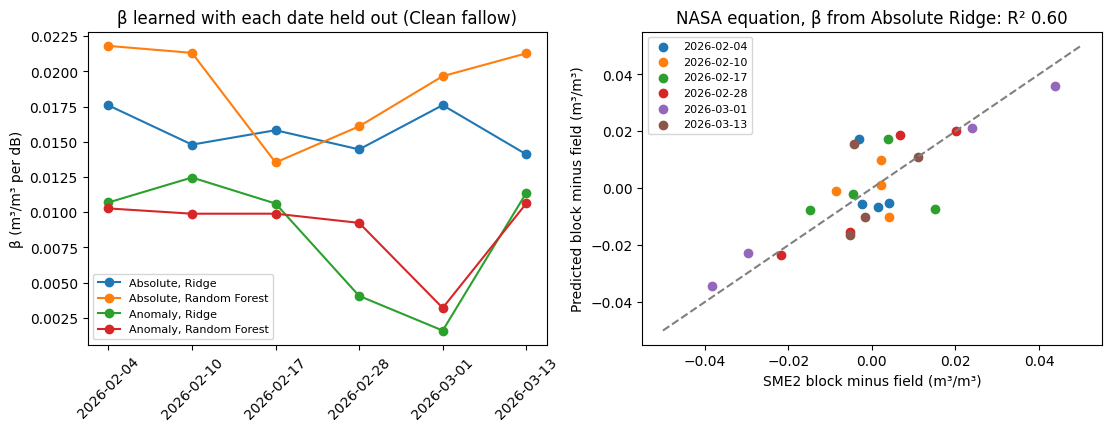

In [55]:
clean = test_predictions[test_predictions["Data"] == "Clean fallow"]
clean_results = results[(results["Data"] == "Clean fallow") & (results["Method"] != "No downscaling")]
best = clean_results.sort_values("NASA_RMSE").iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for column in all_betas.columns:
    if column.endswith("Clean fallow"):
        axes[0].plot(all_betas.index, all_betas[column], marker="o", label=column.replace(", Clean fallow", ""))
axes[0].set_title("β learned with each date held out (Clean fallow)")
axes[0].set_ylabel("β (m³/m³ per dB)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)

one = clean[(clean["Method"] == best["Method"]) & (clean["Model"] == best["Model"])]
for date in one["Date"].unique():
    on_date = one[one["Date"] == date]
    axes[1].scatter(on_date["SM_diff"], on_date["NASA_SM_diff"], label=date)
axes[1].plot([-0.05, 0.05], [-0.05, 0.05], color="grey", linestyle="--")
axes[1].set_title(f"NASA equation, β from {best['Method']} {best['Model']}: R² {best['NASA_R2']:.2f}")
axes[1].set_xlabel("SME2 block minus field (m³/m³)")
axes[1].set_ylabel("Predicted block minus field (m³/m³)")
axes[1].legend(fontsize=8)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Model_Test.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Final β

The β with the lowest NASA-equation RMSE on Clean fallow is retrained on all 24 Clean records. As a check, the same model is
also trained on the morning pass and the evening passes separately.

In [56]:
if best["NASA_R2"] <= 0:
    print("Warning: no β beats no downscaling on unseen dates, so the maps below are not supported")
method = METHODS[best["Method"]]
model, grid = MODELS[best["Model"]]
clean_data = data_sets["Clean fallow"]
beta = learn_beta(tune(model, grid, clean_data, method), clean_data, method)
print(f"Final β from {best['Method']} {best['Model']}: {beta:.4f} m³/m³ per dB")

morning = clean_data["Pass"] == "13:09 UTC"
for label, part in [("Morning pass", clean_data[morning]), ("Evening passes", clean_data[~morning])]:
    part_beta = learn_beta(tune(model, grid, part, method), part, method)
    print(f"{label} ({part['Date'].nunique()} dates): β = {part_beta:.4f}")

Final β from Absolute Ridge: 0.0158 m³/m³ per dB
Morning pass (2 dates): β = 0.0118
Evening passes (4 dates): β = 0.0162


## 6. Results per held-out date

The overall score pools 24 records. Scored one date at a time, the gain comes from Mar 1, the only date where the blocks
differ strongly.

In [57]:
one = clean[(clean["Method"] == best["Method"]) & (clean["Model"] == best["Model"])]


def rmse(values):
    return np.sqrt(np.mean(values ** 2))


per_date = one.groupby(["Date", "Pass"]).apply(lambda d: pd.Series({
    "No downscaling RMSE": rmse(d["SM_diff"]),
    "NASA equation RMSE": rmse(d["SM_diff"] - d["NASA_SM_diff"])}), include_groups=False)
per_date["Better"] = per_date["NASA equation RMSE"] < per_date["No downscaling RMSE"]

rest = one[one["Date"] != "2026-03-01"]
print(f"Without Mar 1: RMSE {rmse(rest['SM_diff'] - rest['NASA_SM_diff']):.4f} vs {rmse(rest['SM_diff']):.4f} with no downscaling")
per_date.round(4)

Without Mar 1: RMSE 0.0111 vs 0.0093 with no downscaling


,,No downscaling RMSE,NASA equation RMSE,Better
Date,Pass,,,
2026-02-04,13:09 UTC,0.0029,0.0121,False
2026-02-10,02:48 UTC,0.0050,0.0089,False
2026-02-17,02:56 UTC,0.0110,0.0137,False
2026-02-28,13:09 UTC,0.0154,0.0079,True
2026-03-01,02:56 UTC,0.0348,0.0058,True
2026-03-13,02:56 UTC,0.0065,0.0121,False


On the five uniform dates the blocks differ by 0.003 to 0.015 m³/m³, less than the noise that β × (radar difference)
adds. SME2 is made from the same radar, so matching it on Mar 1 shows consistency with NASA, not accuracy on the ground.

## 7. Downscaling at 100 m and 50 m

**piece SM = block SME2 + β × (piece HH_dB − block HH_dB)**: NASA's equation (ATBD eq. 4.3.7) without its HV term, one
level finer. The pieces are then shifted to average back exactly to SME2 (pixel-weighted, because pieces at the image edge
hold fewer pixels).

In [58]:
def average_back(table, values, groups):
    t = table.copy()
    t["value"] = values
    return t["value"] - weighted_mean(t, groups, "value")


def downscale(table, beta):
    t = table[table["Block_ID"].isin(MAP_BLOCKS)].copy()
    t["HH_diff"] = t["HH_dB"] - t["Block_HH_dB"]
    t["Downscaled_SM"] = t["Block_SME2"] + average_back(t, beta * t["HH_diff"], ["Date", "Block_ID"])
    t["Change"] = t["Downscaled_SM"] - t["Block_SME2"]
    return t[["Date", "Pass", "Block_ID", "Piece_ID", "Latitude", "Longitude", "Pixels",
              "HH_dB", "Block_HH_dB", "HH_diff", "Block_SME2", "Downscaled_SM", "Change"]]


maps = {size: downscale(table, beta) for size, table in pieces.items()}

summary = []
for size, t in maps.items():
    back = (weighted_mean(t, ["Date", "Block_ID"], "Downscaled_SM") - t["Block_SME2"]).abs().max()
    summary.append([size, len(t), t["Pixels"].median(), back, t["Change"].abs().mean(), t["Change"].abs().max(),
                    (t["Change"].abs() > 0.05).mean()])
map_summary = pd.DataFrame(summary, columns=["Size", "Pieces", "Median_pixels", "Average_back_error",
                                             "Mean_abs_change", "Largest_abs_change", "Share_over_0.05"])
map_summary.round(4)

,Size,Pieces,Median_pixels,Average_back_error,Mean_abs_change,Largest_abs_change,Share_over_0.05
0,100m,96,99.0,0.0,0.0112,0.0775,0.0208
1,50m,384,25.0,0.0,0.0154,0.0904,0.0573


**Detail added per date:** the spread (standard deviation) of soil moisture across the field at each size. The 200 m column
is NASA's; the finer columns show how much detail the radar adds.

In [59]:
spread = pd.DataFrame({
    "SME2 200 m": blocks[blocks["Block_ID"].isin(MAP_BLOCKS)].groupby("Date")["SME2"].std(),
    "100 m": maps["100m"].groupby("Date")["Downscaled_SM"].std(),
    "50 m": maps["50m"].groupby("Date")["Downscaled_SM"].std(),
})
spread.round(4)

,SME2 200 m,100 m,50 m
Date,,,
2026-02-04,0.0034,0.0092,0.0163
2026-02-10,0.0057,0.0126,0.0174
2026-02-17,0.0127,0.0195,0.0224
2026-02-28,0.0178,0.0296,0.0330
2026-03-01,0.0402,0.0445,0.0463
2026-03-13,0.0075,0.0170,0.0220


## 8. Sensitivity to β

The held-out patterns and the 50 m maps with other values of β: a small value, the morning and evening β and the fold
range. Rank correlation shows whether the wetter and drier 50 m pieces stay the same.

These β values were learned from the same six dates, so this table shows sensitivity, not an unseen-date test.

In [60]:
chosen_map = maps["50m"]["Downscaled_SM"]
rows = []
for b in [0.008, 0.0124, best["Beta_low"], beta, 0.0188, best["Beta_high"]]:
    pattern = b * one["HH_diff"]
    error = one["SM_diff"] - (pattern - pattern.groupby(one["Date"]).transform("mean"))
    change = downscale(pieces["50m"], b)["Change"]
    rows.append([b, rmse(error), rmse(error[one["Date"] == "2026-03-01"]), rmse(error[one["Date"] != "2026-03-01"]),
                 change.abs().mean(), (change.abs() > 0.05).mean(), (chosen_map - maps["50m"]["Block_SME2"]).corr(change, method="spearman")])
pd.DataFrame(rows, columns=["β", "RMSE all dates", "RMSE Mar 1", "RMSE other 5", "50 m mean change",
                            "50 m share over 0.05", "50 m rank corr"]).round(4)

,β,RMSE all dates,RMSE Mar 1,RMSE other 5,50 m mean change,50 m share over 0.05,50 m rank corr
0,0.0080,0.0114,0.0215,0.0080,0.0078,0.0000,1.0
1,0.0124,0.0105,0.0143,0.0096,0.0120,0.0339,1.0
2,0.0141,0.0107,0.0115,0.0105,0.0137,0.0443,1.0
3,0.0158,0.0111,0.0087,0.0115,0.0154,0.0573,1.0
4,0.0188,0.0125,0.0040,0.0136,0.0183,0.0625,1.0
5,0.0176,0.0119,0.0058,0.0127,0.0171,0.0599,1.0


## 9. Maps

Distances are EASE-Grid metres: the four blocks cover about 740 m east-west and 217 m north-south on the ground.

In [61]:
def to_grid(table, pieces_per_side, value):
    grid = np.full((pieces_per_side, pieces_per_side * len(MAP_BLOCKS)), np.nan)
    for _, row in table.iterrows():
        piece_row, piece_col = row["Piece_ID"][1:].split("_")
        block_col = MAP_BLOCKS.index(row["Block_ID"])
        grid[int(piece_row), block_col * pieces_per_side + int(piece_col)] = row[value]
    return grid


def draw(ax, grid, title, cmap="YlGnBu", low=None, high=None):
    image = ax.imshow(grid, cmap=cmap, vmin=low, vmax=high, aspect="auto", extent=[0, 800, 200, 0])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("grid metres from west edge (B0_0 → B0_3)", fontsize=8)
    ax.set_ylabel("grid metres from north edge", fontsize=8)
    return image


def sme2_grid(date):
    row = blocks[(blocks["Date"] == date) & blocks["Block_ID"].isin(MAP_BLOCKS)].copy()
    row["Piece_ID"] = "P0_0"
    return to_grid(row, 1, "SME2")


field_spread = spread["SME2 200 m"]
map_dates = [field_spread.idxmin(), field_spread.idxmax()]   # most uniform and most varied dates

**Map 1: SME2 and the downscaled maps** on the most uniform and the most varied date.

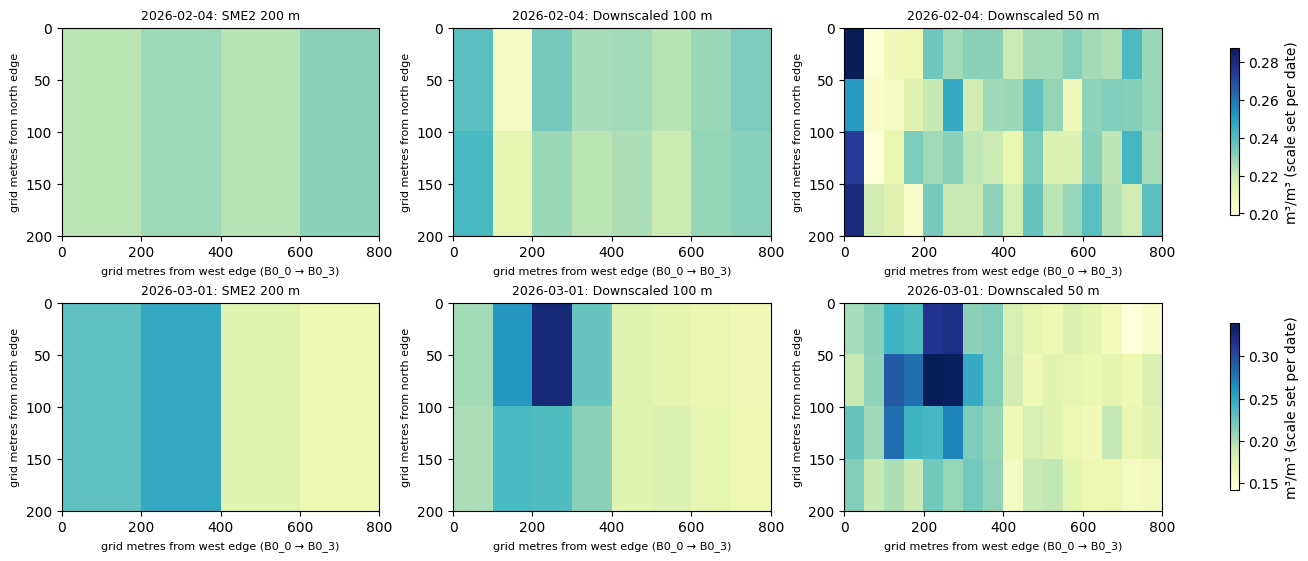

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), layout="constrained")
for r, date in enumerate(map_dates):
    panels = [(sme2_grid(date), "SME2 200 m"),
              (to_grid(maps["100m"][maps["100m"]["Date"] == date], 2, "Downscaled_SM"), "Downscaled 100 m"),
              (to_grid(maps["50m"][maps["50m"]["Date"] == date], 4, "Downscaled_SM"), "Downscaled 50 m")]
    low, high = np.nanmin(panels[2][0]), np.nanmax(panels[2][0])
    for c, (grid, title) in enumerate(panels):
        image = draw(axes[r, c], grid, f"{date}: {title}", low=low, high=high)
    fig.colorbar(image, ax=axes[r, :], label="m³/m³ (scale set per date)", shrink=0.8)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Soil_Moisture_Maps.png"), dpi=150, bbox_inches="tight")
plt.show()

**Map 2: from radar to soil moisture** on the most varied date: the radar difference becomes the moisture pattern.

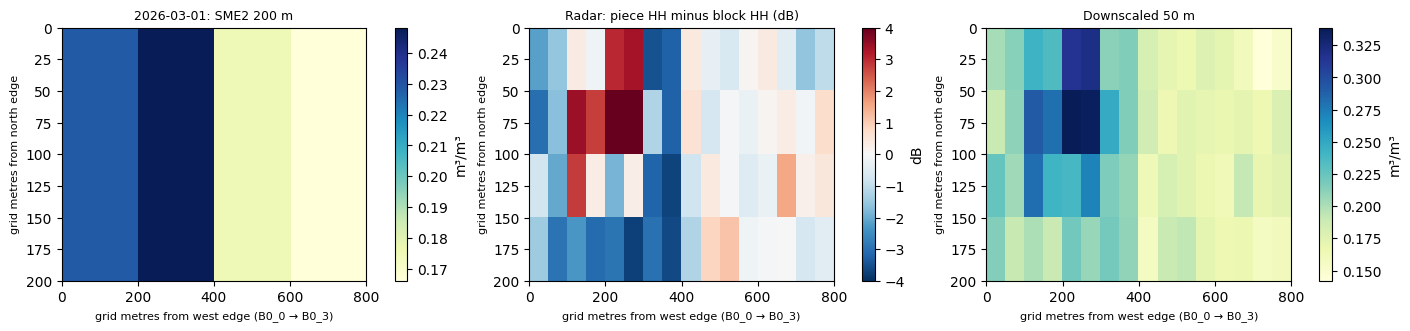

In [63]:
date = map_dates[1]
on_date = maps["50m"][maps["50m"]["Date"] == date]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), layout="constrained")
fig.colorbar(draw(axes[0], sme2_grid(date), f"{date}: SME2 200 m"), ax=axes[0], label="m³/m³")
fig.colorbar(draw(axes[1], to_grid(on_date, 4, "HH_diff"), "Radar: piece HH minus block HH (dB)", "RdBu_r", -4, 4),
             ax=axes[1], label="dB")
fig.colorbar(draw(axes[2], to_grid(on_date, 4, "Downscaled_SM"), "Downscaled 50 m"), ax=axes[2], label="m³/m³")
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Radar_to_Moisture.png"), dpi=150, bbox_inches="tight")
plt.show()

**Map 3: why the choice of β matters.** The same date at 50 m with the chosen β and with the best Anomaly β, on one colour
scale.

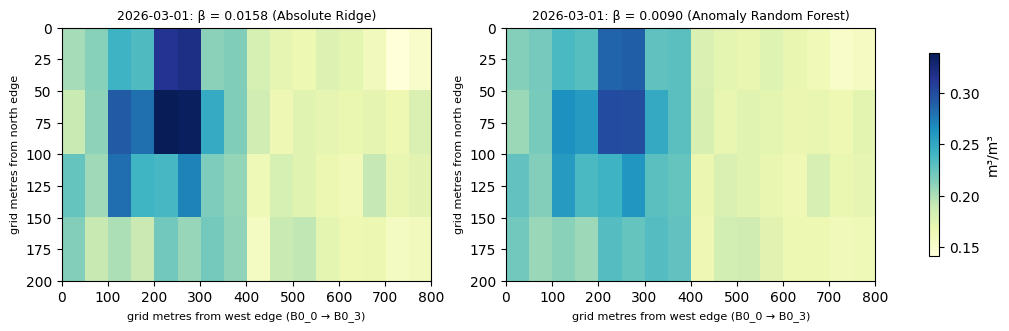

In [64]:
anomaly = clean_results[clean_results["Method"] == "Anomaly"].sort_values("NASA_RMSE").iloc[0]
a_model, a_grid = MODELS[anomaly["Model"]]
anomaly_beta = learn_beta(tune(a_model, a_grid, clean_data, METHODS["Anomaly"]), clean_data, METHODS["Anomaly"])
anomaly_map = downscale(pieces["50m"], anomaly_beta)

chosen = to_grid(on_date, 4, "Downscaled_SM")
other = to_grid(anomaly_map[anomaly_map["Date"] == date], 4, "Downscaled_SM")
low, high = np.nanmin([chosen, other]), np.nanmax([chosen, other])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
draw(axes[0], chosen, f"{date}: β = {beta:.4f} ({best['Method']} {best['Model']})", low=low, high=high)
image = draw(axes[1], other, f"{date}: β = {anomaly_beta:.4f} (Anomaly {anomaly['Model']})", low=low, high=high)
fig.colorbar(image, ax=axes, label="m³/m³", shrink=0.8)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Beta_Comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

**Map 4: all six dates at 50 m**, each on its own colour scale.

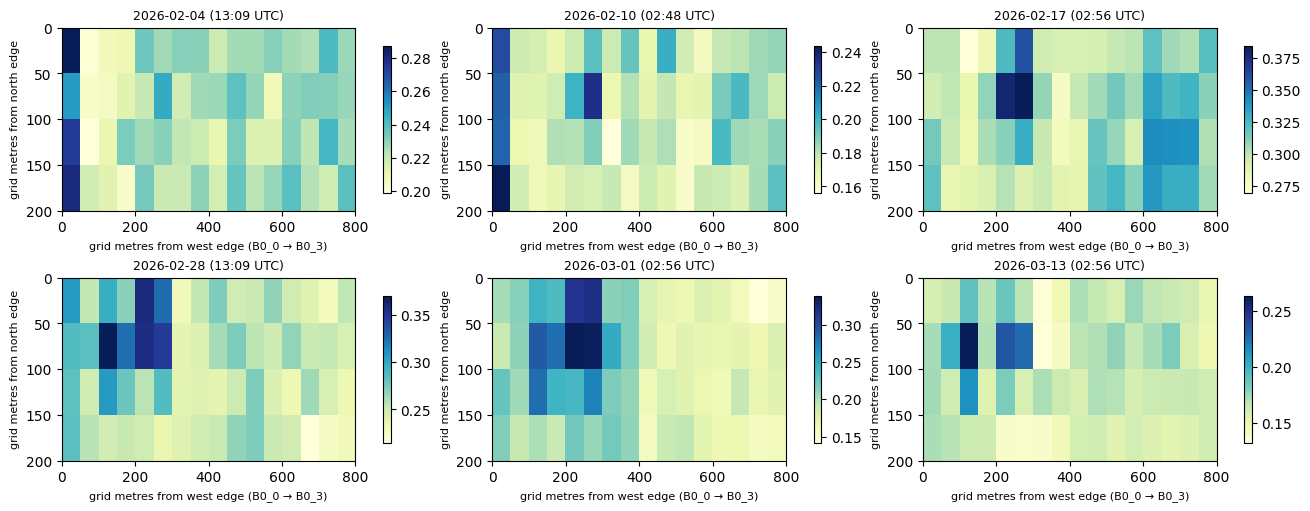

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5), layout="constrained")
for ax, date in zip(axes.flat, sorted(maps["50m"]["Date"].unique())):
    grid = to_grid(maps["50m"][maps["50m"]["Date"] == date], 4, "Downscaled_SM")
    fig.colorbar(draw(ax, grid, f"{date} ({maps['50m'][maps['50m']['Date'] == date]['Pass'].iloc[0]})"), ax=ax, shrink=0.8)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_All_Dates_50m.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. Key results and save

In [66]:
no_change = results[(results["Data"] == "Clean fallow") & (results["Method"] == "No downscaling")].iloc[0]
print(f"Chosen: {best['Method']} {best['Model']}, β = {beta:.4f} m³/m³ per dB")
print(f"Clean fallow, NASA equation: RMSE {best['NASA_RMSE']:.4f} vs {no_change['NASA_RMSE']:.4f} with no downscaling "
      f"({1 - best['NASA_RMSE'] / no_change['NASA_RMSE']:.0%} lower), R² {best['NASA_R2']:.2f}")
print(f"β range across held-out dates: {best['Beta_low']:.4f} to {best['Beta_high']:.4f}")
print(f"Better than no downscaling on {per_date['Better'].sum()} of {len(per_date)} held-out dates")
mixed = results[(results["Data"] == "Clean + Mixed + Edge") & (results["Method"] != "No downscaling")]
print(f"Clean + Mixed + Edge, NASA equation: R² {mixed['NASA_R2'].min():.2f} to {mixed['NASA_R2'].max():.2f}")

with pd.ExcelWriter(OUTPUT_FILE) as writer:
    results.to_excel(writer, sheet_name="Model Test", index=False)
    all_betas.to_excel(writer, sheet_name="Beta per Date")
    per_date.to_excel(writer, sheet_name="Results per Date")
    test_predictions.to_excel(writer, sheet_name="Test Predictions", index=False)
    map_summary.to_excel(writer, sheet_name="Map Summary", index=False)
    spread.to_excel(writer, sheet_name="Spread per Date")
    maps["100m"].to_excel(writer, sheet_name="Map 100m", index=False)
    maps["50m"].to_excel(writer, sheet_name="Map 50m", index=False)
print("Saved", OUTPUT_FILE, "and five figures")

Chosen: Absolute Ridge, β = 0.0158 m³/m³ per dB
Clean fallow, NASA equation: RMSE 0.0104 vs 0.0166 with no downscaling (37% lower), R² 0.60
β range across held-out dates: 0.0141 to 0.0176
Better than no downscaling on 2 of 6 held-out dates
Clean + Mixed + Edge, NASA equation: R² 0.10 to 0.27
Saved ../Processed Data/Final_Soil_Moisture_Results.xlsx and five figures
